# 02 · Calibración del factor VIIRS → MODIS

**Responsables:** Datos (4) y Backend 2 · ML (2).

VIIRS ve unas 5 veces más focos que MODIS porque sus píxeles son más chicos (375 m contra 1 km). Si se juntan las dos series sin ajustar, en 2012 aparece un salto que no es del fuego sino del satélite. El factor

> **k = celdas-día Aqua / celdas-día VIIRS**

lleva VIIRS a la escala MODIS. Este cuaderno decide cómo calcularlo antes de que Datos lo fije en `harmonize.py`:

1. **Ventana de calibración:** ¿la hora de paso de Aqua y el cociente se mantienen en 2012–2021?
2. **Grilla** para contar celdas-día: 0,1°, 0,25° o 0,5°.
3. **Tipo de factor:** uno solo, uno por estación o uno por mes.
4. **Factor para NOAA-20**, que reemplaza a S-NPP desde el 2 de noviembre de 2026.

**Entrada:** los CSV anuales de NASA FIRMS de California en `ml/data/raw/` (en cualquier subcarpeta). FIRMS los publica por país; `download_firms.py` baja los de Estados Unidos y los recorta a California:

| Archivo | Satélites | Años que hacen falta |
|---|---|---|
| `modis_AAAA_California.csv` | Terra y Aqua | 2012–2025 |
| `viirs-snpp_AAAA_California.csv` | VIIRS S-NPP | 2012–2025 |
| `viirs-jpss1_AAAA_California.csv` | VIIRS NOAA-20 | 2018–2025 (solo sección 7) |

Las funciones están en `kindra/ml/calibration.py`, con sus pruebas en `ml/tests/test_calibration.py`. Acá queda solo el análisis.

**Regla:** ninguna cifra se escribe a mano. La tabla de Decisión queda en «pendiente» hasta correr el cuaderno con datos reales.

## 0. Configuración

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ML = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ML))  # permite importar `kindra` sin instalar el paquete

from kindra.ml import calibration as cal

from kindra.config import CALIBRATION_YEARS as CALIB_YEARS  # 2012–2021, antes de la deriva orbital
from kindra.config import MODIS_MIN_CONFIDENCE as MODIS_MIN_CONF  # MODIS: confianza 0–100

VIIRS_START = "2012-01-20"  # primer día de VIIRS S-NPP en FIRMS
HOLDOUT_YEARS = range(2022, 2026)  # reservados para la validación final (validation.py)
YEARS = range(2012, max(HOLDOUT_YEARS) + 1)
NOAA20_OVERLAP = range(2018, max(CALIB_YEARS) + 1)  # años completos de NOAA-20 con Aqua estable
RESOLUTIONS = [0.1, 0.25, 0.5]  # grados; grillas candidatas
FEW_CELL_DAYS = 50  # un mes con menos celdas-día Aqua es una muestra chica

RAW = ML / "data" / "raw"
FIGURES = ML.parent / "docs" / "capturas"
FIGURES.mkdir(parents=True, exist_ok=True)
CALIB_LABEL = f"{min(CALIB_YEARS)}–{max(CALIB_YEARS)}"

for file in sorted(RAW.rglob("*.csv")):
    print(file.relative_to(RAW))

modis\modis_2000_California.csv
modis\modis_2001_California.csv
modis\modis_2002_California.csv
modis\modis_2003_California.csv
modis\modis_2004_California.csv
modis\modis_2005_California.csv
modis\modis_2006_California.csv
modis\modis_2007_California.csv
modis\modis_2008_California.csv
modis\modis_2009_California.csv
modis\modis_2010_California.csv
modis\modis_2011_California.csv
modis\modis_2012_California.csv
modis\modis_2013_California.csv
modis\modis_2014_California.csv
modis\modis_2015_California.csv
modis\modis_2016_California.csv
modis\modis_2017_California.csv
modis\modis_2018_California.csv
modis\modis_2019_California.csv
modis\modis_2020_California.csv
modis\modis_2021_California.csv
modis\modis_2022_California.csv
modis\modis_2023_California.csv
modis\modis_2024_California.csv
modis\modis_2025_California.csv
viirs-jpss1\viirs-jpss1_2018_California.csv
viirs-jpss1\viirs-jpss1_2019_California.csv
viirs-jpss1\viirs-jpss1_2020_California.csv
viirs-jpss1\viirs-jpss1_2021_Califor

## 1. Carga y limpieza

Se leen todos los CSV juntos y se dejan los focos que cuentan para el método:

- vegetación (`type = 0`), cuando la columna existe;
- MODIS con confianza ≥ 30 y VIIRS con confianza nominal o alta;
- dentro del recuadro de California (`REGION_BBOX` en `config.py`).

Si aparece un código de satélite sin reconocer, hay que agregarlo a `SATELLITES` en `calibration.py`; si no, esos focos se pierden.

In [2]:
fires = cal.load_firms(RAW, first_day=VIIRS_START, last_day=f"{max(YEARS)}-12-31")
print("Satélites sin reconocer:", cal.unknown_satellites(fires) or "ninguno")

clean = cal.clean_fires(fires, modis_min_confidence=MODIS_MIN_CONF)
print(f"{len(fires):,} focos leídos → {len(clean):,} después de limpiar".replace(",", "."))

Satélites sin reconocer: ninguno


2.067.293 focos leídos → 1.811.157 después de limpiar


### ¿Están todos los años?

Para calibrar hacen falta Aqua **y** S-NPP en cada año de la ventana. Si falta alguno, el cuaderno se detiene acá y dice qué archivos pedir.

In [3]:
coverage = cal.yearly_coverage(clean, YEARS, ["Terra", "Aqua", "SNPP", "NOAA20"])
display(coverage)

missing = [year for year in CALIB_YEARS if (coverage.loc[year, ["Aqua", "SNPP"]] == 0).any()]
assert not missing, (
    f"Faltan datos para calibrar en {missing}. Se necesitan modis_AAAA_California.csv "
    "y viirs-snpp_AAAA_California.csv de esos años: correr download_firms.yearly()."
)

sat,Terra,Aqua,SNPP,NOAA20
año,,,,
2012,5906,6103,46469,0
2013,5360,5543,41974,0
2014,4336,4495,38420,0
2015,5389,5905,50624,0
2016,4764,4664,33340,0
2017,9869,9456,78639,0
2018,11811,11323,89377,80985
2019,2962,2721,19773,19833
2020,25176,22616,227225,227872


## 2. ¿Por qué calibrar solo en 2012–2021? La hora de paso

Aqua y S-NPP cruzan California cerca de la 13:30 hora solar. Si la hora de Aqua se corre en los últimos años, Aqua derivó de órbita: ya no mira el fuego a la misma hora que VIIRS y el cociente deja de ser comparable. La mediana usa solo los pasos diurnos.

sat,Aqua,NOAA20,SNPP,Terra
año,,,,
2012,13.16,NaN,12.88,10.97
2013,13.20,NaN,12.97,10.96
2014,13.18,NaN,13.07,10.99
2015,13.18,NaN,13.05,11.04
2016,13.16,NaN,13.02,10.99
2017,13.12,NaN,12.94,10.98
2018,13.16,12.97,13.04,10.99
2019,13.16,12.93,12.94,10.94
2020,13.11,12.99,12.98,11.00


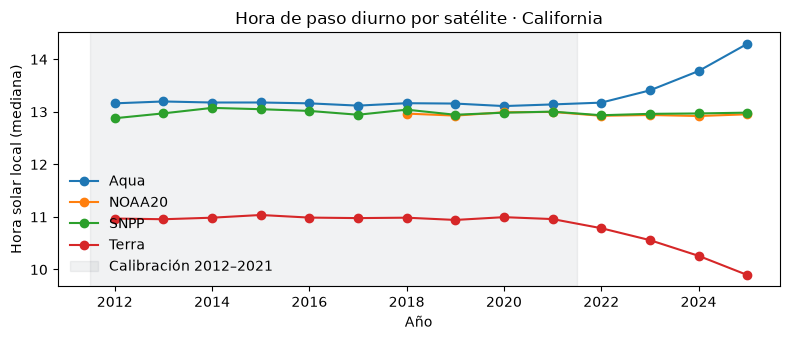

In [4]:
hours = cal.overpass_hour(clean)

fig, ax = plt.subplots(figsize=(8, 3.5))
for sat in hours.columns:
    ax.plot(hours.index, hours[sat], marker="o", label=sat)
ax.axvspan(min(CALIB_YEARS) - 0.5, max(CALIB_YEARS) + 0.5, color="#1B2835", alpha=0.06,
           label=f"Calibración {CALIB_LABEL}")
ax.set(xlabel="Año", ylabel="Hora solar local (mediana)", title="Hora de paso diurno por satélite · California")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "calibracion_hora_de_paso.png", dpi=200)
hours.round(2)

## 3. Celdas-día y cociente por año

Una celda con fuego en un día cuenta una sola vez por satélite. Se cuentan con las tres grillas candidatas. Si la ventana es buena, el cociente anual se mantiene parejo dentro de la franja gris y se mueve después.

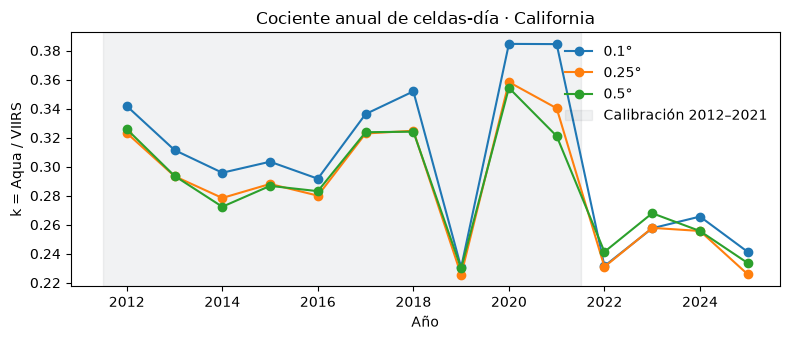

In [5]:
counts = {res: cal.monthly_cell_days(clean, res) for res in RESOLUTIONS}

fig, ax = plt.subplots(figsize=(8, 3.5))
for res, c in counts.items():
    yearly = c.groupby("year")[["a", "v"]].sum()
    ax.plot(yearly.index, cal.ratio(yearly["a"], yearly["v"]), marker="o", label=f"{res}°")
ax.axvspan(min(CALIB_YEARS) - 0.5, max(CALIB_YEARS) + 0.5, color="#1B2835", alpha=0.06,
           label=f"Calibración {CALIB_LABEL}")
ax.set(xlabel="Año", ylabel="k = Aqua / VIIRS", title="Cociente anual de celdas-día · California")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "calibracion_k_anual.png", dpi=200)

## 4. Factor por mes y su intervalo

`k` por mes del año en la ventana de calibración, con un intervalo del 90 % que remuestrea años completos. Un intervalo angosto indica un factor estable con esa grilla; muchos meses con pocas celdas-día indican que la grilla es demasiado fina.

In [6]:
factors = {res: cal.monthly_factors(c, CALIB_YEARS) for res, c in counts.items()}

stability = pd.DataFrame({
    res: {
        "k medio": f["k"].mean(),
        "ancho medio del intervalo (% de k)": ((f["k_high"] - f["k_low"]) / f["k"]).mean() * 100,
        f"meses con < {FEW_CELL_DAYS} celdas-día Aqua": int((f["aqua"] < FEW_CELL_DAYS).sum()),
    }
    for res, f in factors.items()
}).T
stability.round(3)

,k medio,ancho medio del intervalo (% de k),meses con < 50 celdas-día Aqua
0.10,0.298,23.989,0.0
0.25,0.289,22.849,0.0
0.50,0.291,21.389,0.0


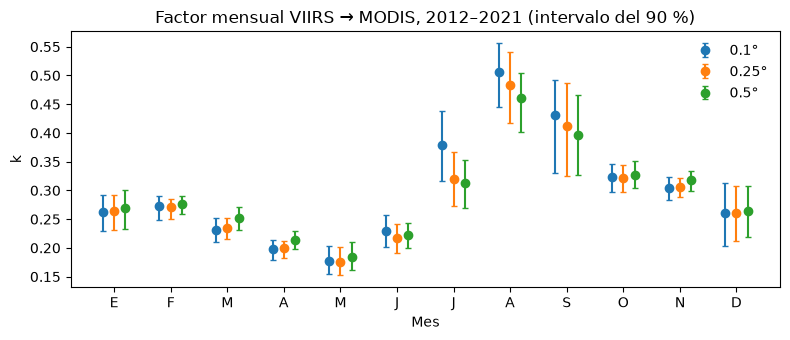

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for offset, (res, f) in zip([-0.2, 0, 0.2], factors.items()):  # separa las grillas en cada mes
    # `k` usa todos los años y puede quedar apenas fuera de su intervalo; la barra no admite
    # largos negativos.
    yerr = [(f["k"] - f["k_low"]).clip(lower=0), (f["k_high"] - f["k"]).clip(lower=0)]
    ax.errorbar(f["month"] + offset, f["k"], yerr=yerr, fmt="o", capsize=2, label=f"{res}°")
ax.set(xticks=range(1, 13), xticklabels=list("EFMAMJJASOND"), xlabel="Mes", ylabel="k",
       title=f"Factor mensual VIIRS → MODIS, {CALIB_LABEL} (intervalo del 90 %)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "calibracion_k_mensual.png", dpi=200)

## 5. ¿Qué tipo de factor predice mejor?

**Validación dejando un año afuera:** se calibra con nueve años de la ventana y se predice Aqua en el décimo (`Aqua ≈ VIIRS × k`), diez veces. Gana la combinación de grilla y factor que menos se equivoca.

- **único:** un solo `k` para todo el año.
- **estacional:** un `k` por estación (DEF, MAM, JJA, SON).
- **mensual:** un `k` por mes, como propone el tutorial.

Métricas: error absoluto medio por mes (celdas-día), error del total anual (%) y correlación `r` mes a mes.

In [8]:
loyo = cal.compare_factors(counts, lambda c: cal.leave_one_year_out(c, CALIB_YEARS))
loyo.round(3)

MAE mensual (celdas-día)  error anual (%)      r
grilla factor                                                      
0.10   único                         61.040           13.748  0.960
       estacional                    45.434           12.491  0.954
       mensual                       38.832           10.117  0.959
0.25   único                         40.045           11.958  0.907
       estacional                    32.275           11.231  0.908
       mensual                       27.198            9.893  0.926
0.50   único                         29.503           11.085  0.886
       estacional                    24.585           10.655  0.888
       mensual                       20.471            9.796  0.914

## 6. Vista previa del holdout 2022–2025

Calibra en 2012–2021 y predice Aqua en años que nunca vio. Si el error crece mucho respecto de la tabla anterior, es la deriva de Aqua de la sección 2: se informa en la validación y en el pitch, no es un error del método. La validación oficial la hace `validation.py`.

In [9]:
if coverage.loc[list(HOLDOUT_YEARS), ["Aqua", "SNPP"]].eq(0).any(axis=None):
    print(f"Faltan datos de {min(HOLDOUT_YEARS)}–{max(HOLDOUT_YEARS)} para el holdout.")
else:
    holdout = cal.compare_factors(counts, lambda c: cal.train_test(c, CALIB_YEARS, HOLDOUT_YEARS))
    display(holdout.round(3))

MAE mensual (celdas-día)  error anual (%)      r
grilla factor                                                      
0.10   único                         61.418           34.557  0.707
       estacional                    43.418           27.284  0.828
       mensual                       40.445           21.801  0.829
0.25   único                         42.458           27.940  0.698
       estacional                    33.361           23.804  0.810
       mensual                       33.072           20.026  0.787
0.50   único                         32.842           22.683  0.691
       estacional                    26.475           20.060  0.803
       mensual                       26.045           17.483  0.786

## 7. Factor para NOAA-20

Desde el 2 de noviembre de 2026 la serie usa NOAA-20, porque S-NPP dejó de producir datos. Es el mismo sensor VIIRS, pero pasa unos 50 minutos antes o después, así que su `k` puede no ser igual al de S-NPP. Se calcula con los años completos en que NOAA-20 y Aqua estable coinciden (2018–2021).

In [10]:
n20_years = [y for y in NOAA20_OVERLAP if (coverage.loc[y, ["Aqua", "NOAA20"]] > 0).all()]

if len(n20_years) < len(NOAA20_OVERLAP):
    print(f"Faltan viirs-jpss1_AAAA_California.csv o modis_AAAA_California.csv de "
          f"{sorted(set(NOAA20_OVERLAP) - set(n20_years))}.")
else:
    res = 0.1  # TODO(Backend 2): usar la grilla elegida en la sección 5
    n20 = cal.monthly_cell_days(clean, res, viirs="NOAA20")
    snpp = cal.monthly_factors(counts[res], n20_years).set_index("month")
    noaa20 = cal.monthly_factors(n20, n20_years).set_index("month")
    display(pd.DataFrame({"k S-NPP": snpp["k"], "k NOAA-20": noaa20["k"],
                          "NOAA-20 / S-NPP": noaa20["k"] / snpp["k"]}).round(3))

,k S-NPP,k NOAA-20,NOAA-20 / S-NPP
month,,,
1,0.259,0.341,1.316
2,0.288,0.391,1.360
3,0.241,0.287,1.191
4,0.198,0.187,0.943
5,0.131,0.124,0.946
6,0.198,0.187,0.941
7,0.408,0.407,0.999
8,0.532,0.525,0.986
9,0.479,0.469,0.980


## Decisión

Completada con las tablas de arriba (corrida del 15/11/2026, CSV de California 2000–2025).

| Decisión | Valor | Motivo (cifra de la tabla) |
|---|---|---|
| Ventana de calibración | **2012–2021** | Sección 2: la hora de paso de Aqua se mantiene en 13,1–13,2 h hasta 2022 y deriva después (13,41 h en 2023, 14,29 h en 2025); Terra baja de 11,0 a 9,9 h. |
| Grilla para el factor | **0,1°** | Sección 5: con el factor mensual las tres grillas quedan cerca en error anual (10,1 %, 9,9 % y 9,8 %), y 0,1° tiene la mejor correlación mes a mes (r = 0,959) y ningún mes con menos de 50 celdas-día Aqua (sección 4). Es además la grilla de las zonas y del mapa. |
| Tipo de factor | **mensual** | Sección 5: gana en las tres grillas (0,1°: error anual 10,1 % contra 12,5 % estacional y 13,7 % único) y en el holdout 2022–2025 (21,8 % contra 27,3 % y 34,6 %). |
| k medio de California | **0,298** (0,1°) | Sección 4: intervalo del 90 % de ancho medio 24 % de k. VIIRS ve unas 3,4 veces más celdas-día que Aqua. |
| Factor para NOAA-20 | **propio, calibrado en 2018–2021** | Sección 7: igual a S-NPP de abril a diciembre (0,94–1,00 veces), pero 1,19–1,36 veces más alto de enero a marzo. |

**Límite conocido: el factor depende del tamaño del fuego.** En los meses de calibración a 0,1°, k sube con la cantidad de celdas-día VIIRS: 0,23 en el cuarto de meses con menos fuego, 0,37 en el cuarto con más, y hasta 0,63 en agosto de 2021. En un incendio grande las celdas se llenan para los dos sensores y la ventaja de resolución de VIIRS pesa menos. Por eso la serie armonizada queda por debajo de MODIS en los meses extremos (Los Ángeles, enero de 2025: 15 armonizada contra 30 de Aqua). El cociente contra la mediana no cambia, porque la mediana usa la misma serie.

**Para después:** factor que dependa del tamaño del fuego, y factor por condado con contracción hacia el de California (`ml/data/boundaries/california.geojson`).
